In [1]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import rankdata

In [2]:
DATA_DIR = Path(
    "/blue/bala1s/krishnap.kalivel/"
    "TLFHydrodynamics/thinfilm-closure-ml/"
    "datasets/BasC/param_space/ClosureData"
)

RE = 40
CA = 0.10
BETA = 45

In [3]:
re_tag = f"{RE:03d}"
ca_tag = f"{CA:.3f}".replace(".", "_")
beta_tag = f"{BETA:g}".replace(".", "_")

filepath = DATA_DIR / (
    f"thinfilm_closure_data_Re{re_tag}_"
    f"Ca{ca_tag}_theta{beta_tag}.h5"
)

if not filepath.is_file():
    raise FileNotFoundError(filepath)

FILE_PATH = DATA_DIR / filepath

In [4]:
QOIS = [
    # "dudy_wall",
    # "int_u2_dy",
    # "u_interface",
    # "int_px_dy",
    "delta_Tw_ML",
    "delta_Mx_ML",
    "delta_Dx_ML",
    "delta_Px_ML",
]

In [5]:
def fluctuations(field):
    """Subtract the time mean separately at each spatial location."""
    field = np.where(np.isfinite(field), field, np.nan)
    return field - np.nanmean(field, axis=1, keepdims=True)


def conditional_pearson(a, b):
    """Pearson correlation over the selected x,t observations."""
    if a.size < 2:
        return np.nan

    ac = a - np.mean(a)
    bc = b - np.mean(b)
    denominator = np.sqrt(np.dot(ac, ac) * np.dot(bc, bc))

    if denominator <= 0:
        return np.nan

    return np.clip(np.dot(ac, bc) / denominator, -1.0, 1.0)


def conditional_spearman(a, b):
    """Spearman correlation over the selected x,t observations."""
    a = np.asarray(a, dtype=float).ravel()
    b = np.asarray(b, dtype=float).ravel()

    if a.size != b.size:
        raise ValueError("a and b must have the same number of values.")

    valid = np.isfinite(a) & np.isfinite(b)
    a, b = a[valid], b[valid]

    if a.size < 2:
        return np.nan

    # Average ranks handle tied values.
    return conditional_pearson(
        rankdata(a, method="average"),
        rankdata(b, method="average"),
    )

In [6]:
def read_spatial_field(f, name, nx, nt):
    """Return a field with shape (nx, nt)."""
    array = np.asarray(f[name][:], dtype=float)

    if array.shape == (nx, nt):
        return array
    if array.shape == (nt, nx):
        return array.T

    raise ValueError(f"{name}: unexpected shape {array.shape}")


In [7]:
MAX_OFFSET = 100
HX_TOL = 0.05
H_TOL = 0.05
# Add "All" here to also plot the unconditional correlation.
# REGIONS = ["Peaks", "Troughs","NonFlat","All", "Lowlands", "Highlands"]
REGIONS = ["All", "Lowlands", "Highlands"]

In [8]:
with h5py.File(FILE_PATH, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    nx, nt = len(x), len(t)

    h = read_spatial_field(f, "h", nx, nt)
    q = read_spatial_field(f, "q", nx, nt)
    hx = read_spatial_field(f, "h_x", nx, nt)
    hxx = read_spatial_field(f, "h_xx", nx, nt)

dx = x[1] - x[0]
kappa = hxx / (1 + hx**2)**(3/2)

if dx <= 0 or not np.allclose(np.diff(x), dx):
    raise ValueError("Expected an increasing uniform spatial grid.")

K = MAX_OFFSET
if K < 0 or 2 * K >= nx:
    raise ValueError("Invalid MAX_OFFSET.")

In [9]:
n_offsets = np.arange(-K, K + 1)
start, stop = K, nx - K

hp = fluctuations(h)
qp = fluctuations(q)
kappap = fluctuations(kappa)

h_center = h[start:stop, :]
hx_center = hx[start:stop, :]

# Require complete finite h,q neighborhoods.
# This makes every separation use the same observations.
base_valid = np.isfinite(h_center)

for n in n_offsets:
    base_valid &= (
        np.isfinite(hp[start + n:stop + n, :])
        & np.isfinite(qp[start + n:stop + n, :])
        & np.isfinite(kappap[start + n:stop + n, :])
    )

region_masks = {
    "All": base_valid,
    # "Peaks": (
    #     base_valid
    #     & np.isfinite(hx_center)
    #     & (h_center > 1.2)
    #     & (np.abs(hx_center) <= HX_TOL)
    # ),
    # "Troughs": (
    #     base_valid
    #     & np.isfinite(hx_center)
    #     & (h_center < 0.8)
    #     & (np.abs(hx_center) <= HX_TOL)
    # ),
    # "NonFlat": (
    #     base_valid
    #     & np.isfinite(hx_center)
    #     & ((np.abs(h_center - 1) >= H_TOL) | (np.abs(hx_center) >= HX_TOL))
    # ),
    "Lowlands": (
        base_valid
        & np.isfinite(hx_center)
        & (h_center > 1.15)
        & (np.abs(hx_center) <= HX_TOL)
    ),
    "Highlands": (
        base_valid
        & np.isfinite(hx_center)
        & (h_center < 0.85)
    ),
}

In [10]:
correlation_results = {}

# Load one QoI at a time to limit memory usage.
with h5py.File(FILE_PATH, "r") as f:
    for name in QOIS:
        y = read_spatial_field(f, name, nx, nt)
        yp = fluctuations(y)
        y_center = yp[start:stop, :]

        correlation_results[name] = {}

        for region in REGIONS:
            mask = region_masks[region] & np.isfinite(y_center)
            y_selected = y_center[mask]

            Rh = np.full(len(n_offsets), np.nan)
            Rq = np.full(len(n_offsets), np.nan)
            Rk = np.full(len(n_offsets), np.nan)

            for i, n in enumerate(n_offsets):
                h_selected = hp[start + n:stop + n, :][mask]
                q_selected = qp[start + n:stop + n, :][mask]
                kappa_selected = kappap[start + n:stop + n, :][mask]

                Rh[i] = conditional_pearson(y_selected, h_selected)
                Rq[i] = conditional_pearson(y_selected, q_selected)
                Rk[i] = conditional_pearson(y_selected, kappa_selected)

            correlation_results[name][region] = {
                "h": Rh,
                "q": Rq,
                "kappa": Rk,
                "n_points": int(mask.sum()),
            }

            print(
                f"{name}, {region}: "
                f"{mask.sum():,} selected x,t observations"
            )

        del y, yp, y_center

delta_Tw_ML, All: 2,929,304 selected x,t observations
delta_Tw_ML, Lowlands: 294,762 selected x,t observations
delta_Tw_ML, Highlands: 1,394,487 selected x,t observations
delta_Mx_ML, All: 2,929,304 selected x,t observations
delta_Mx_ML, Lowlands: 294,762 selected x,t observations
delta_Mx_ML, Highlands: 1,394,487 selected x,t observations
delta_Dx_ML, All: 2,929,304 selected x,t observations
delta_Dx_ML, Lowlands: 294,762 selected x,t observations
delta_Dx_ML, Highlands: 1,394,487 selected x,t observations
delta_Px_ML, All: 2,929,304 selected x,t observations
delta_Px_ML, Lowlands: 294,762 selected x,t observations
delta_Px_ML, Highlands: 1,394,487 selected x,t observations


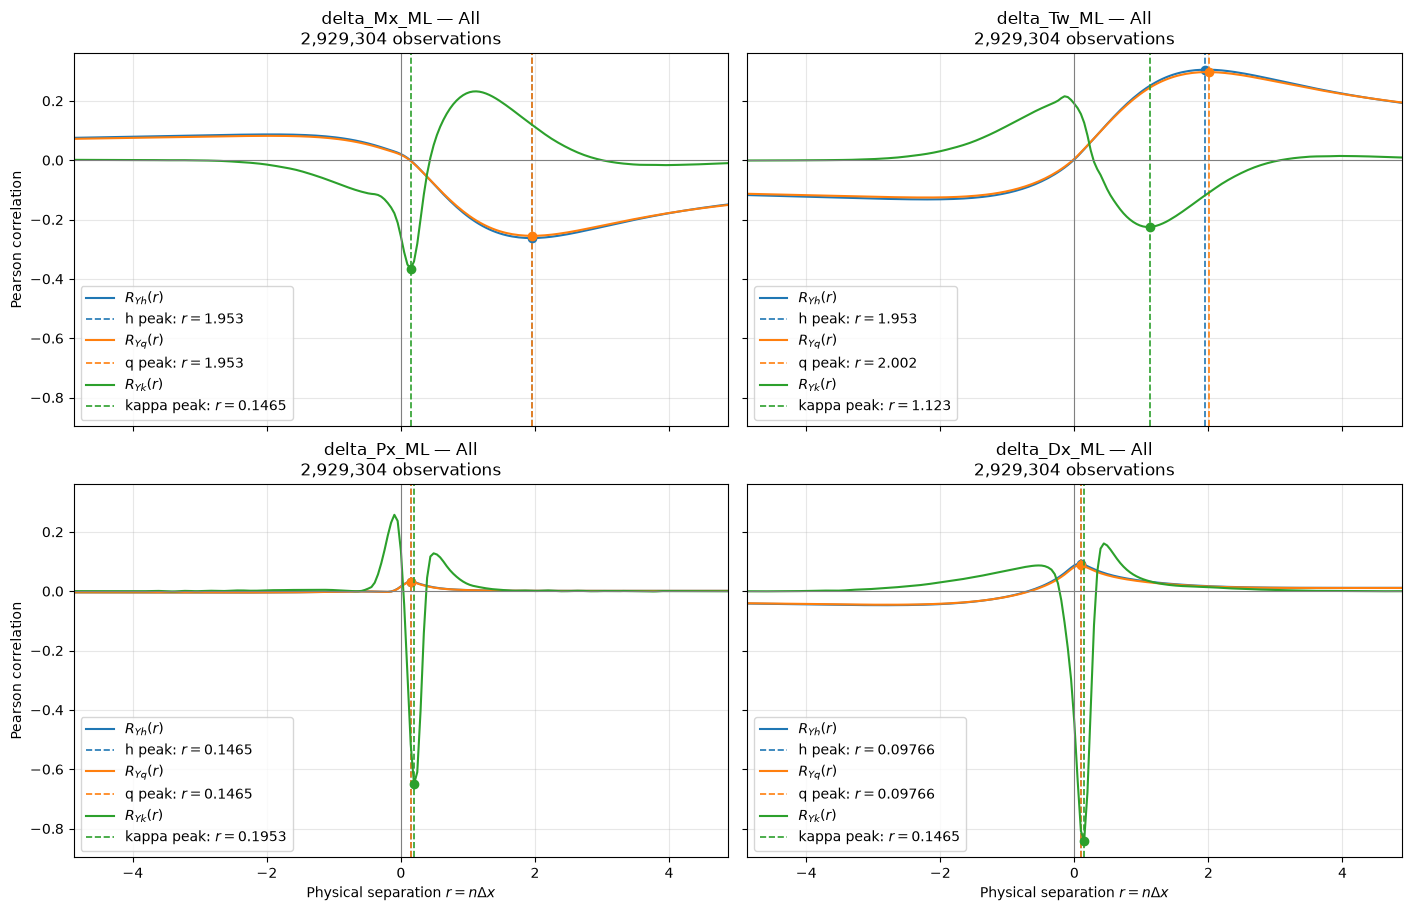

In [11]:
PLOT_QOIS = [
    "delta_Mx_ML", "delta_Tw_ML",
    "delta_Px_ML", "delta_Dx_ML",
]
PLOT_REGION = "All"

if len(PLOT_QOIS) != 4:
    raise ValueError("Select exactly four QoIs for a 2 × 2 plot.")

for name in PLOT_QOIS:
    if (
        name not in correlation_results
        or PLOT_REGION not in correlation_results[name]
    ):
        raise KeyError(f"No calculated results for {name}/{PLOT_REGION}")

dx = float(x[1] - x[0])
distances = np.asarray(n_offsets) * dx

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, name in zip(axes.flat, PLOT_QOIS):
    result = correlation_results[name][PLOT_REGION]

    for field, color, label in [
        ("h", "tab:blue", r"$R_{Yh}(r)$"),
        ("q", "tab:orange", r"$R_{Yq}(r)$"),
        ("kappa", "tab:green", r"$R_{Yk}(r)$"),
    ]:
        correlation = np.asarray(result[field], dtype=float)

        ax.plot(
            distances, correlation,
            color=color,
            linewidth=1.5,
            label=label,
        )

        if np.any(np.isfinite(correlation)):
            # peak_index = np.nanargmax(correlation)
            peak_index = np.nanargmax(np.abs(correlation))
            peak_distance = distances[peak_index]
            peak_value = correlation[peak_index]

            ax.axvline(
                peak_distance,
                color=color,
                linestyle="--",
                linewidth=1.2,
                label=rf"{field} peak: $r={peak_distance:.4g}$",
            )
            ax.plot(
                peak_distance, peak_value,
                marker="o",
                color=color,
                markersize=6,
            )

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_xlim(distances.min(), distances.max())
    ax.set_title(
        f"{name} — {PLOT_REGION}\n"
        f"{result['n_points']:,} observations"
    )
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10)

for ax in axes[-1, :]:
    ax.set_xlabel(r"Physical separation $r=n\Delta x$")

for ax in axes[:, 0]:
    ax.set_ylabel("Pearson correlation")

plt.show()

In [12]:
PLOT_QOIS = ["dudy_wall", "int_u2_dy", "int_px_dy"]
PLOT_REGIONS = ["All"]  

if not PLOT_QOIS or not PLOT_REGIONS:
    raise ValueError("Select at least one QoI and one region.")

for name in PLOT_QOIS:
    for region in PLOT_REGIONS:
        if name not in correlation_results or region not in correlation_results[name]:
            raise KeyError(f"No calculated results for {name}/{region}")

fig, axes = plt.subplots(
    len(PLOT_QOIS),
    len(PLOT_REGIONS),
    figsize=(6.5 * len(PLOT_REGIONS), 4 * len(PLOT_QOIS)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

for row, name in enumerate(PLOT_QOIS):
    for col, region in enumerate(PLOT_REGIONS):
        ax = axes[row, col]
        result = correlation_results[name][region]

        ax.plot(
            n_offsets, result["h"],
            color="tab:blue", linewidth=1.5,
            label=r"$R_{Yh}(n)$",
        )
        ax.plot(
            n_offsets, result["q"],
            color="tab:orange", linewidth=1.5,
            label=r"$R_{Yq}(n)$",
        )

        ax.axhline(0, color="gray", linewidth=0.8)
        ax.axvline(0, color="gray", linewidth=0.8)
        ax.set_ylim(-1, 1)
        ax.set_xlim(-K, K)
        ax.set_title(
            f"{name} — {region}\n"
            f"{result['n_points']:,} observations"
        )
        ax.grid(alpha=0.3)
        ax.legend()

        if col == 0:
            ax.set_ylabel("Pearson correlation")
        if row == len(PLOT_QOIS) - 1:
            ax.set_xlabel(r"Offset $n$ (distance $n\Delta x$)")

plt.show()

KeyError: 'No calculated results for dudy_wall/All'

In [ ]:
#Non-standardized PDFs

PDF_QOIS = ["dudy_wall", "int_u2_dy"]
PDF_REGIONS = ["Peaks", "Troughs","NonFlat","All"]
PDF_REGIONS = ["Lowlands", "Highlands","NonFlat","All"]

USE_FLUCTUATIONS = False
N_BINS = 100
LOG_PDF = False

if not PDF_QOIS or not PDF_REGIONS:
    raise ValueError("Select at least one QoI and region.")

for region in PDF_REGIONS:
    if region not in region_masks:
        raise KeyError(f"Region not calculated: {region}")

start, stop = K, len(x) - K

fig, axes = plt.subplots(
    len(PDF_QOIS), 1,
    figsize=(10, 3.5 * len(PDF_QOIS)),
    squeeze=False,
    constrained_layout=True,
)

with h5py.File(FILE_PATH, "r") as f:
    for row, name in enumerate(PDF_QOIS):
        field = read_spatial_field(f, name, len(x), len(t))

        if USE_FLUCTUATIONS:
            field = fluctuations(field)

        center = field[start:stop, :]
        region_values = {}

        for region in PDF_REGIONS:
            mask = region_masks[region] & np.isfinite(center)
            values = center[mask]

            if values.size == 0:
                print(f"{name}/{region}: no eligible points; skipped")
                continue

            region_values[region] = values

        ax = axes[row, 0]

        if not region_values:
            ax.set_title(f"{name}: no eligible points")
            continue

        # Shared bin edges allow direct comparisons between regions.
        pooled = np.concatenate(list(region_values.values()))
        bins = np.histogram_bin_edges(pooled, bins=N_BINS)

        for region, values in region_values.items():
            ax.hist(
                values,
                bins=bins,
                density=True,
                histtype="step",
                linewidth=1.8,
                label=f"{region} ({values.size:,} points)",
            )

        ax.set_xlabel(
            f"{name} fluctuation" if USE_FLUCTUATIONS else name
        )
        ax.set_ylabel("Probability density")
        ax.set_title(name)
        ax.legend()
        ax.grid(alpha=0.3)

        if LOG_PDF:
            ax.set_yscale("log")

plt.show()

In [ ]:
#Standardized PDFs

PDF_QOIS = ["delta_Tw_ML", "delta_Px_ML"]
PDF_REGIONS = ["Lowlands", "Highlands"]

N_STD = 1  # Change to 2 for ±2 standard deviations
USE_FLUCTUATIONS = False
N_BINS = 100
LOG_PDF = False

if not PDF_QOIS or not PDF_REGIONS:
    raise ValueError("Select at least one QoI and region.")
if N_STD <= 0:
    raise ValueError("N_STD must be positive.")

for region in PDF_REGIONS:
    if region not in region_masks:
        raise KeyError(f"Region not calculated: {region}")

start, stop = K, len(x) - K
bins = np.linspace(-N_STD, N_STD, N_BINS + 1)

fig, axes = plt.subplots(
    len(PDF_QOIS), 1,
    figsize=(10, 3.5 * len(PDF_QOIS)),
    squeeze=False,
    constrained_layout=True,
)

with h5py.File(FILE_PATH, "r") as f:
    for row, name in enumerate(PDF_QOIS):
        field = read_spatial_field(f, name, len(x), len(t))

        if USE_FLUCTUATIONS:
            field = fluctuations(field)

        center = field[start:stop, :]
        ax = axes[row, 0]
        plotted = False

        for region in PDF_REGIONS:
            mask = region_masks[region] & np.isfinite(center)
            values = center[mask]

            if values.size < 2:
                print(f"{name}/{region}: insufficient points; skipped")
                continue

            mean = np.mean(values)
            std = np.std(values, ddof=0)

            if std <= 0:
                print(f"{name}/{region}: zero variance; skipped")
                continue

            z = (values - mean) / std

            # Normalize using ALL observations, preserving omitted tail mass.
            counts, _ = np.histogram(z, bins=bins)
            density = counts / (values.size * np.diff(bins))

            ax.stairs(
                density,
                bins,
                linewidth=1.8,
                label=region,
            )
            plotted = True

        ax.set_xlim(-N_STD, N_STD)
        ax.set_xlabel(r"Standardized QoI: $(Y-\mu)/\sigma$")
        ax.set_ylabel("Probability density")
        ax.set_title(name)
        ax.grid(alpha=0.3)

        if plotted:
            ax.legend()
        if LOG_PDF:
            ax.set_yscale("log")

plt.show()

In [ ]:
#Non-standardized PDFs

PDF_QOIS = ["delta_Tw_ML", "delta_Mx_ML"]
PDF_REGIONS = ["Lowlands", "Highlands"]

USE_FLUCTUATIONS = False
N_BINS = 100
LOG_PDF = False

if not PDF_QOIS or not PDF_REGIONS:
    raise ValueError("Select at least one QoI and region.")

for region in PDF_REGIONS:
    if region not in region_masks:
        raise KeyError(f"Region not calculated: {region}")

start, stop = K, len(x) - K

fig, axes = plt.subplots(
    len(PDF_QOIS), 1,
    figsize=(10, 3.5 * len(PDF_QOIS)),
    squeeze=False,
    constrained_layout=True,
)

with h5py.File(FILE_PATH, "r") as f:
    for row, name in enumerate(PDF_QOIS):
        field = read_spatial_field(f, name, len(x), len(t))

        if USE_FLUCTUATIONS:
            field = fluctuations(field)

        center = field[start:stop, :]
        region_values = {}

        for region in PDF_REGIONS:
            mask = region_masks[region] & np.isfinite(center)
            values = center[mask]

            if values.size == 0:
                print(f"{name}/{region}: no eligible points; skipped")
                continue

            region_values[region] = values

        ax = axes[row, 0]

        if not region_values:
            ax.set_title(f"{name}: no eligible points")
            continue

        # Shared bin edges allow direct comparisons between regions.
        pooled = np.concatenate(list(region_values.values()))
        bins = np.histogram_bin_edges(pooled, bins=N_BINS)

        for region, values in region_values.items():
            ax.hist(
                values,
                bins=bins,
                density=True,
                histtype="step",
                linewidth=1.8,
                label=f"{region} ({values.size:,} points)",
            )

        ax.set_xlabel(
            f"{name} fluctuation" if USE_FLUCTUATIONS else name
        )
        ax.set_ylabel("Probability density")
        ax.set_title(name)
        ax.legend()
        ax.grid(alpha=0.3)

        if LOG_PDF:
            ax.set_yscale("log")

plt.show()